In [52]:
import pandas as pd
import torch 
import torch.nn as nn

In [53]:
data = pd.read_csv("powerplant_data.csv")
data.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [54]:
data.drop_duplicates(inplace = True)

In [55]:
X = data.drop("PE",axis=1)
y = data['PE']

In [56]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=42)

In [57]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
X_train_scaled = ss.fit_transform(X_train)
X_test_scaled = ss.transform(X_test)

In [58]:
X_test_scaled

array([[ 1.82791845,  1.10911073, -0.12838811, -1.41526257],
       [-1.51496271, -1.24739821,  0.04249291, -0.46852793],
       [-1.47853907, -1.42015128,  0.39948198, -1.08325512],
       ...,
       [ 0.29138025,  0.55473042, -0.35848534,  1.29145382],
       [ 0.38716095, -0.8320056 ,  0.40794144, -1.99713129],
       [-0.39662192, -1.28587503,  1.65655725, -0.53766762]],
      shape=(2859, 4))

In [59]:
import torch
import torch.nn as nn

X_train_tensor = torch.tensor(X_train_scaled,dtype = torch.float32)
y_train_tensor = torch.tensor(y_train.values,dtype = torch.float32).view(-1,1)

X_test_tensor = torch.tensor(X_test_scaled, dtype = torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype = torch.float32).view(-1,1)

In [60]:
from torch.utils.data import TensorDataset , DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor,y_test_tensor)

In [61]:
train_loader = DataLoader(train_dataset,batch_size=32, shuffle = True)
test_loader = DataLoader(test_dataset, batch_size=32)

In [62]:
#Define our ANN model
class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            #1st hidden layer
            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),

            #2nd hidden layer
            nn.Linear(6,6),
            nn.ReLU(),

            #output layer
            nn.Linear(6,1),
        )

    def forward(self,x):
        return self.model(x)

In [63]:
import torch.optim as optim

model = ANN()

#loss , optimizer 
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [64]:
# Train ANN
train_losses = []
val_losses = []
best_val_loss = float("inf")
epochs = 50
for epoch in range(epochs):
    model.train()
    running_loss = 0.0 #total training loss for 1 epoch
    for xb, yb in train_loader:
        #xb = feature of batch one
        #yb = labels of batch one
        optimizer.zero_grad()

        output = model(xb) #forward_prop
        loss = criterion(output,yb) # compute loss
        loss.backward() #back_prop
        optimizer.step() #params_update

        running_loss += loss.item() #bydefault tensor hoga but hame isko float me convert karna hoga

    epoch_train_loss = running_loss/len(train_loader)
    train_losses.append(epoch_train_loss)

    #validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for xb,yb in test_loader:
            output = model(xb)
            loss = criterion(output,yb)
            running_val_loss += loss

    epoch_val_loss = running_val_loss/len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss = {epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(),"Best_model.pt")

epoch 1/50 ==> train loss = 206032.3283492823 & val loss = 204955.140625
epoch 2/50 ==> train loss = 199455.7191985646 & val loss = 191970.140625
epoch 3/50 ==> train loss = 177450.7677930622 & val loss = 159930.09375
epoch 4/50 ==> train loss = 137240.71340460525 & val loss = 112559.296875
epoch 5/50 ==> train loss = 88740.67441686602 & val loss = 65655.109375
epoch 6/50 ==> train loss = 49461.99169220993 & val loss = 35235.640625
epoch 7/50 ==> train loss = 28523.698330965908 & val loss = 22537.41796875
epoch 8/50 ==> train loss = 20504.84991309061 & val loss = 17830.9453125
epoch 9/50 ==> train loss = 16921.094263980263 & val loss = 15016.8232421875
epoch 10/50 ==> train loss = 14286.339668529456 & val loss = 12641.8837890625
epoch 11/50 ==> train loss = 11974.770783492822 & val loss = 10492.83203125
epoch 12/50 ==> train loss = 9843.382006485497 & val loss = 8523.8984375
epoch 13/50 ==> train loss = 7919.835138494318 & val loss = 6754.7158203125
epoch 14/50 ==> train loss = 6173.99

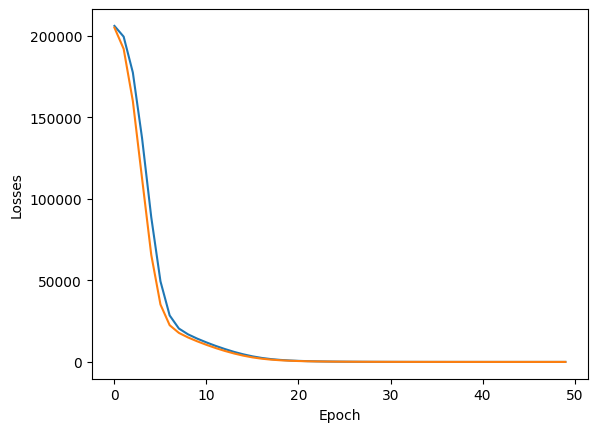

In [65]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
        "Training Loss" : train_losses,
        "Validation Loss" : val_losses
})

plt.plot(loss_df['Training Loss'],label = ['Training Loss'])
plt.plot(loss_df['Validation Loss'],label = ['Validation Loss'])
plt.xlabel('Epoch')
plt.ylabel('Losses')
plt.show()

In [66]:
model.load_state_dict(torch.load("Best_model.pt"))

<All keys matched successfully>

In [68]:
model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = criterion(train_preds,y_train_tensor)
    test_mse_loss = criterion(test_preds,y_test_tensor)

print("training MSE: ",train_mse_loss.item())
print("test MSE: ",test_mse_loss.item())

training MSE:  21.546846389770508
test MSE:  21.667314529418945


In [69]:
from sklearn.metrics import r2_score

r2_score(y_test,test_preds)

0.9265937295048882

In [70]:
predicted_df = pd.DataFrame(test_preds.numpy(),columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values,columns=["Actual Values"])

pd.concat([predicted_df,actual_df],axis=1)

,Predicted Values,Actual Values
0,426.807648,429.38
1,480.691010,485.29
2,487.183746,480.40
3,450.201385,452.30
4,447.010864,446.47
...,...,...
2854,455.400757,459.10
2855,436.676147,443.65
2856,444.654694,445.21
2857,455.557495,460.30
